---
# PHẦN 1: CẤU HÌNH MÔI TRƯỜNG
Kiểm tra GPU, phiên bản Python/PyTorch/CUDA/Transformers; chỉ cài thêm thư viện còn thiếu hoặc quá cũ.

## 1.1 Kiểm tra phiên bản và GPU

In [1]:
# 1.1 Kiểm tra môi trường: Python, thư viện, GPU
import sys
import platform
from importlib.metadata import version as pkg_version, PackageNotFoundError


def get_pkg_version(pip_name):
    # Lấy phiên bản thư viện bằng metadata (không import, tránh nạp sớm module cũ)
    try:
        return pkg_version(pip_name)
    except PackageNotFoundError:
        return None


print("Python:", sys.version.split()[0], "|", platform.platform())
for pip_name in ["torch", "transformers", "accelerate", "datasets", "huggingface_hub",
                 "pandas", "pyarrow", "Pillow", "matplotlib", "tqdm", "seaborn", "scikit-learn"]:
    print(f"{pip_name:<16}: {get_pkg_version(pip_name) or 'CHƯA CÀI'}")

import torch

print("\nPyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)
print("torch.cuda.is_available():", torch.cuda.is_available())
if torch.cuda.is_available():
    for gpu_id in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(gpu_id)
        print(f"GPU {gpu_id}: {props.name} | VRAM {props.total_memory / 1024 ** 3:.1f} GB | "
              f"compute capability {props.major}.{props.minor}")
else:
    print("CẢNH BÁO: Không phát hiện GPU. Hãy bật GPU trong Kaggle Settings -> Accelerator. "
          "Chạy trên CPU sẽ cực kỳ chậm với model 4B.")

Python: 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
torch           : 2.11.0+cu130
transformers    : 5.20.2
accelerate      : 1.15.0
datasets        : 4.8.5
huggingface_hub : 1.33.0
pandas          : 2.3.3
pyarrow         : 23.0.1
Pillow          : 13.0.0
matplotlib      : 3.10.0
tqdm            : 4.67.3
seaborn         : 0.13.2
scikit-learn    : 1.6.1

PyTorch: 2.11.0+cu130 | CUDA build: 13.0
torch.cuda.is_available(): True
GPU 0: Tesla T4 | VRAM 14.6 GB | compute capability 7.5
GPU 1: Tesla T4 | VRAM 14.6 GB | compute capability 7.5


## 1.2 Cài thư viện 
Qwen3-VL yêu cầu `transformers >= 4.57.0` (lớp `Qwen3VLForConditionalGeneration`). Cell này **chỉ** cài/nâng cấp những gói chưa có hoặc quá cũ.

In [2]:
# 1.2 Cài đặt thư viện còn thiếu (không cài lại gói đã tương thích)
import subprocess
from packaging.version import Version

MIN_TRANSFORMERS = "4.57.0"  # Phiên bản tối thiểu có Qwen3-VL

# Gói cơ bản: chỉ cài khi chưa có
basic_packages = ["accelerate", "datasets", "huggingface_hub", "pandas", "pyarrow",
                  "Pillow", "matplotlib", "tqdm", "seaborn", "scikit-learn"]
missing_packages = [name for name in basic_packages if get_pkg_version(name) is None]

# Transformers: cài khi thiếu hoặc cũ hơn mức tối thiểu
transformers_version = get_pkg_version("transformers")
transformers_too_old = transformers_version is None or Version(transformers_version) < Version(MIN_TRANSFORMERS)

NEED_RESTART = False
if missing_packages:
    print("Cài các gói còn thiếu:", missing_packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing_packages)
else:
    print("Các gói cơ bản đã đầy đủ.")

if transformers_too_old:
    print(f"transformers hiện tại = {transformers_version}; cần >= {MIN_TRANSFORMERS}. Đang nâng cấp...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"transformers>={MIN_TRANSFORMERS}"])
    NEED_RESTART = True
else:
    print(f"transformers {transformers_version} đã hỗ trợ Qwen3-VL.")

if NEED_RESTART:
    raise RuntimeError("Đã nâng cấp transformers. Hãy chọn Run -> Restart Session rồi chạy lại notebook từ đầu "
                       "(cell này sẽ không cài lại vì phiên bản đã đủ).")

Các gói cơ bản đã đầy đủ.
transformers 5.20.2 đã hỗ trợ Qwen3-VL.


## 1.3 Import và cấu hình tham số
Mọi tham số có thể chỉnh nằm trong cell này.

In [3]:
# 1.3 Import thư viện và khai báo cấu hình
import os
import io
import re
import gc
import sys
import json
import time
import random
import socket
import textwrap
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image

# ---------------- Cấu hình dataset ----------------
DATASET_NAME = "lmms-lab-encoder/POPE"
DATA_SOURCE = "hub_parquet"      # "hub_parquet": tải file Parquet từ Hub | "hf_datasets": load_dataset | "local_parquet": đọc file Parquet có sẵn
LOCAL_PARQUET_DIR = None         # Ví dụ: "/kaggle/input/pope-parquet" (dùng khi DATA_SOURCE = "local_parquet")
SPLIT = "auto"                   # "auto" | tên split cụ thể (vd "test") | "all" (gộp mọi file Parquet)

# ---------------- Cấu hình model ----------------
MODEL_NAME = "Qwen/Qwen3-VL-4B-Instruct"
MODEL_PATH = None                # Ví dụ: "/kaggle/input/qwen3-vl-4b-instruct/..." nếu model đã thêm vào Kaggle Input (chạy offline)
DTYPE_OVERRIDE = None            # None = tự chọn | "bfloat16" | "float16" | "float32"

# ---------------- Cấu hình inference ----------------
MAX_SAMPLES = None               # None = chạy toàn bộ; số nguyên = giới hạn số mẫu (dùng để chạy thử)
SAMPLING = "head"                # "head": lấy N mẫu đầu | "random": lấy N mẫu ngẫu nhiên (POPE sắp xếp theo category nên nên dùng random khi chạy thử)
SEED = 42
BATCH_SIZE = 1                   # Ưu tiên 1 để tiết kiệm VRAM
MAX_NEW_TOKENS = 8               # Câu trả lời chỉ cần 1 từ Yes/No
DO_SAMPLE = False                # False = greedy decoding (tái lập được)
TEMPERATURE = 0.7                # Chỉ có tác dụng khi DO_SAMPLE = True
MAX_IMAGE_SIDE = 1024            # Thu nhỏ ảnh nếu cạnh dài hơn giá trị này (None = giữ nguyên)
OOM_FALLBACK_SIDES = (768, 512, 384)  # Khi gặp CUDA OOM sẽ thử lại với ảnh nhỏ dần

# ---------------- Checkpoint / resume ----------------
SAVE_INTERVAL = 100              # Số mẫu giữa mỗi lần ghi checkpoint
RESUME = True                    # Tiếp tục từ kết quả đã có
RETRY_FAILED = True              # Khi resume: chạy lại các mẫu có status = error
RESUME_FROM = None               # Đường dẫn vlm_predictions.jsonl cũ (vd trong /kaggle/input/...) nếu phiên mới chưa có output

# ---------------- Kiểm tra dữ liệu ----------------
CHECK_ALL_IMAGES = True          # True: giải mã thử toàn bộ ảnh (chậm hơn một chút nhưng đầy đủ)
NUM_PREVIEW = 8                  # Số mẫu hiển thị ảnh

# ---------------- Đường dẫn ----------------
IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd()
OUTPUT_DIR = WORK_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = OUTPUT_DIR / "vlm_predictions.csv"
JSONL_PATH = OUTPUT_DIR / "vlm_predictions.jsonl"
SUMMARY_PATH = OUTPUT_DIR / "inference_summary.json"

# Cố định seed để tái lập
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Chạy trên Kaggle:", IS_KAGGLE)
print("Thư mục output  :", OUTPUT_DIR.resolve())

Chạy trên Kaggle: True
Thư mục output  : /kaggle/working/output


---
# PHẦN 2: TẢI VÀ ĐỌC DATASET
Dataset POPE được lưu dạng Parquet và có thể gồm nhiều file trong cùng một split. Notebook sẽ liệt kê file, chọn split, gộp tất cả file thuộc split đó thành **một** `Dataset` thống nhất (memory-mapped nên không nạp toàn bộ bytes ảnh vào RAM).

## 2.1 Hàm tiện ích: tìm file Parquet theo split

In [5]:
# 2.1 Các hàm liệt kê / nhóm file Parquet theo split
KNOWN_SPLITS = {"train", "test", "validation", "val", "dev"}


def infer_split_from_path(file_path):
    # Suy ra tên split từ đường dẫn file Parquet (vd data/test-00000-of-00004.parquet -> test)
    path = Path(file_path)
    match = re.match(r"^([A-Za-z_]+)-\d+-of-\d+", path.name)
    if match:
        return match.group(1).lower()
    for part in reversed(path.parts[:-1]):
        if part.lower() in KNOWN_SPLITS:
            return part.lower()
    stem_without_digits = re.sub(r"[-_]?\d+$", "", path.stem)
    return (stem_without_digits or path.stem).lower()


def group_files_by_split(file_paths):
    # Nhóm danh sách file theo split và sắp xếp tên file để thứ tự ổn định
    groups = {}
    for file_path in sorted(str(p) for p in file_paths):
        groups.setdefault(infer_split_from_path(file_path), []).append(file_path)
    return groups


def list_hub_parquet_files(repo_id):
    # Liệt kê toàn bộ file .parquet của dataset trên Hugging Face Hub
    from huggingface_hub import HfApi
    files = HfApi().list_repo_files(repo_id, repo_type="dataset")
    return group_files_by_split([f for f in files if f.lower().endswith(".parquet")])


def list_local_parquet_files(local_dir):
    # Liệt kê file .parquet trong thư mục local (vd Kaggle Input); nhóm theo đường dẫn tương đối
    base = Path(local_dir)
    if not base.exists():
        raise FileNotFoundError(f"Không tìm thấy thư mục: {base}")
    relative_to_abs = {str(p.relative_to(base)): str(p) for p in base.rglob("*.parquet")}
    groups = group_files_by_split(relative_to_abs.keys())
    return {split: [relative_to_abs[rel] for rel in rels] for split, rels in groups.items()}


def resolve_split(available_groups, requested):
    # Chọn split cần chạy; báo lỗi rõ ràng nếu không xác định được
    if not available_groups:
        raise ValueError("Không tìm thấy file Parquet nào.")
    if requested == "all":
        return "all"
    if requested not in (None, "auto"):
        if requested not in available_groups:
            raise ValueError(f"Split '{requested}' không tồn tại. Các split có sẵn: {sorted(available_groups)}")
        return requested
    if len(available_groups) == 1:
        return next(iter(available_groups))
    if "test" in available_groups:
        return "test"
    raise ValueError(f"Có nhiều split {sorted(available_groups)}; hãy đặt SPLIT cụ thể ở cell 1.3.")

## 2.2 Tải dataset và gộp các file Parquet

In [6]:
# 2.2 Tải dataset POPE, gộp mọi file Parquet của split được chọn thành một Dataset
from datasets import load_dataset, Image as HFImage
from huggingface_hub import hf_hub_download

SPLIT_NAME = None
PARQUET_FILES_USED = []

try:
    if DATA_SOURCE == "hf_datasets":
        # Dùng Hugging Face Dataset API trực tiếp
        from datasets import get_dataset_split_names
        split_names = get_dataset_split_names(DATASET_NAME)
        SPLIT_NAME = resolve_split({name: [] for name in split_names}, SPLIT)
        if SPLIT_NAME == "all":
            raise ValueError("SPLIT='all' chỉ hỗ trợ với hub_parquet / local_parquet.")
        pope_ds = load_dataset(DATASET_NAME, split=SPLIT_NAME)
    else:
        if DATA_SOURCE == "hub_parquet":
            groups = list_hub_parquet_files(DATASET_NAME)
        elif DATA_SOURCE == "local_parquet":
            if not LOCAL_PARQUET_DIR:
                raise ValueError("Hãy đặt LOCAL_PARQUET_DIR khi DATA_SOURCE = 'local_parquet'.")
            groups = list_local_parquet_files(LOCAL_PARQUET_DIR)
        else:
            raise ValueError(f"DATA_SOURCE không hợp lệ: {DATA_SOURCE}")

        print("Các split / số file Parquet phát hiện được:", {k: len(v) for k, v in groups.items()})
        SPLIT_NAME = resolve_split(groups, SPLIT)
        selected_files = sorted(f for files in groups.values() for f in files) if SPLIT_NAME == "all" else groups[SPLIT_NAME]

        if DATA_SOURCE == "hub_parquet":
            local_files = [hf_hub_download(DATASET_NAME, filename=f, repo_type="dataset") for f in selected_files]
        else:
            local_files = selected_files
        PARQUET_FILES_USED = selected_files
        # Gộp tất cả file Parquet thành một Dataset duy nhất (cùng schema)
        pope_ds = load_dataset("parquet", data_files=[str(p) for p in local_files], split="train")
except Exception as exc:
    raise RuntimeError(f"Không tải được dataset: {exc}\n"
                       "Kiểm tra Internet (Settings -> Internet: On) hoặc dùng DATA_SOURCE = 'local_parquet'.") from exc

# Nếu image là Image feature thì tắt tự giải mã: luôn nhận dạng dict {bytes, path}, hàm load_image sẽ xử lý
if "image" in pope_ds.column_names and isinstance(pope_ds.features["image"], HFImage):
    pope_ds = pope_ds.cast_column("image", HFImage(decode=False))

print("\nSplit đang dùng :", SPLIT_NAME)
print("File Parquet    :", PARQUET_FILES_USED if PARQUET_FILES_USED else "(từ load_dataset)")
print("Tổng số mẫu     :", len(pope_ds))

Các split / số file Parquet phát hiện được: {'adversarial': 1, 'popular': 1, 'random': 1, 'test': 3}


data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B / 85.0MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]


Split đang dùng : test
File Parquet    : ['data/test-00000-of-00003.parquet', 'data/test-00001-of-00003.parquet', 'data/test-00002-of-00003.parquet']
Tổng số mẫu     : 9000


## 2.3 Kiểm tra cấu trúc dataset
Tên cột, kiểu dữ liệu, giá trị null, trùng lặp, nhãn và phân bố theo category.

In [7]:
# 2.3 Kiểm tra cấu trúc dataset
print("Các cột:", pope_ds.column_names)
print("\nFeatures (kiểu dữ liệu):")
for column_name, feature in pope_ds.features.items():
    print(f"  {column_name:<14}: {feature}")

REQUIRED_COLUMNS = ["question", "image"]
OPTIONAL_COLUMNS = ["id", "question_id", "answer", "category", "image_source"]
missing_required = [c for c in REQUIRED_COLUMNS if c not in pope_ds.column_names]
if missing_required:
    raise ValueError(f"Dataset thiếu cột bắt buộc: {missing_required}")
missing_optional = [c for c in OPTIONAL_COLUMNS if c not in pope_ds.column_names]
if missing_optional:
    print("CẢNH BÁO - thiếu các cột tuỳ chọn:", missing_optional)

# Bảng metadata (không chứa ảnh) để thống kê nhanh
meta_df = pope_ds.remove_columns(["image"]).to_pandas()
print("\nKiểu dữ liệu của metadata:")
print(meta_df.dtypes)

print("\nSố giá trị null theo cột (không gồm image):")
print(meta_df.isna().sum())

if "id" in meta_df.columns:
    print("\nSố ID trùng lặp:", int(meta_df["id"].duplicated().sum()))
if "question_id" in meta_df.columns:
    print("Số question_id trùng lặp:", int(meta_df["question_id"].duplicated().sum()))
print("Số dòng trùng lặp hoàn toàn (không tính ảnh):", int(meta_df.duplicated().sum()))

if "category" in meta_df.columns:
    print("\nSố mẫu theo category:")
    print(meta_df["category"].value_counts(dropna=False))
if "answer" in meta_df.columns:
    # Chỉ để kiểm tra định dạng nhãn; KHÔNG dùng trong inference
    print("\nGiá trị cột answer (chỉ để kiểm tra dữ liệu):")
    print(meta_df["answer"].value_counts(dropna=False))
if "image_source" in meta_df.columns:
    print("\nSố mẫu theo image_source (top 10):")
    print(meta_df["image_source"].value_counts(dropna=False).head(10))

Các cột: ['id', 'question_id', 'question', 'answer', 'image_source', 'image', 'category']

Features (kiểu dữ liệu):
  id            : Value('string')
  question_id   : Value('string')
  question      : Value('string')
  answer        : Value('string')
  image_source  : Value('string')
  image         : Image(mode=None, decode=False)
  category      : Value('string')

Kiểu dữ liệu của metadata:
id              object
question_id     object
question        object
answer          object
image_source    object
category        object
dtype: object

Số giá trị null theo cột (không gồm image):
id              0
question_id     0
question        0
answer          0
image_source    0
category        0
dtype: int64

Số ID trùng lặp: 0
Số question_id trùng lặp: 6000
Số dòng trùng lặp hoàn toàn (không tính ảnh): 0

Số mẫu theo category:
category
adversarial    3000
popular        3000
random         3000
Name: count, dtype: int64

Giá trị cột answer (chỉ để kiểm tra dữ liệu):
answer
yes    4500
no

## 2.4 Hàm xử lý ảnh `load_image`
Không giả định mọi ảnh cùng kiểu: hàm xử lý `PIL.Image`, `dict {bytes, path}`, `bytes` thuần và đường dẫn file; luôn trả về PIL Image RGB hoặc ném `ImageLoadError` có thông điệp rõ ràng.

In [8]:
# 2.4 Hàm xử lý ảnh: chuẩn hoá mọi dạng dữ liệu ảnh về PIL Image RGB
class ImageLoadError(Exception):
    # Lỗi khi không thể đọc / giải mã ảnh
    pass


def load_image(image_data):
    # Nhận dữ liệu ảnh từ dataset (dict bytes/path, PIL Image, bytes, đường dẫn) và trả về PIL Image RGB
    try:
        if image_data is None:
            raise ValueError("dữ liệu ảnh là None")
        if isinstance(image_data, Image.Image):
            image = image_data
        elif isinstance(image_data, dict):
            raw_bytes = image_data.get("bytes")
            image_path = image_data.get("path")
            if raw_bytes:
                image = Image.open(io.BytesIO(raw_bytes))
            elif image_path and Path(image_path).is_file():
                image = Image.open(image_path)
            else:
                raise ValueError(f"dict không có bytes và path không hợp lệ (path={image_path!r})")
        elif isinstance(image_data, (bytes, bytearray)):
            image = Image.open(io.BytesIO(bytes(image_data)))
        elif isinstance(image_data, (str, Path)):
            if not Path(image_data).is_file():
                raise ValueError(f"không tìm thấy file ảnh: {image_data}")
            image = Image.open(image_data)
        else:
            raise TypeError(f"kiểu dữ liệu ảnh không được hỗ trợ: {type(image_data).__name__}")
        image.load()  # Ép giải mã thật sự để phát hiện ảnh hỏng
        return image.convert("RGB")
    except Exception as exc:
        raise ImageLoadError(f"{type(exc).__name__}: {exc}") from exc

## 2.5 Kiểm tra ảnh có giải mã được không

In [9]:
# 2.5 Kiểm tra null / ảnh lỗi: giải mã thử ảnh bằng load_image
def scan_images(dataset, check_all=True, preview_limit=64, batch_size=64):
    # Trả về (số ảnh đã kiểm tra, danh sách (row_index, lỗi))
    limit = len(dataset) if check_all else min(preview_limit, len(dataset))
    bad_rows = []
    checked = 0
    image_only = dataset.select_columns(["image"])
    for batch in tqdm(image_only.iter(batch_size=batch_size), total=(len(dataset) + batch_size - 1) // batch_size,
                      desc="Kiểm tra ảnh"):
        for image_data in batch["image"]:
            if checked >= limit:
                break
            try:
                load_image(image_data)
            except ImageLoadError as exc:
                bad_rows.append((checked, str(exc)))
            checked += 1
        if checked >= limit:
            break
    return checked, bad_rows


checked_count, bad_image_rows = scan_images(pope_ds, check_all=CHECK_ALL_IMAGES)
print(f"Đã kiểm tra {checked_count} ảnh; không giải mã được: {len(bad_image_rows)}")
if bad_image_rows:
    print("Một số dòng lỗi (row_index, lỗi):", bad_image_rows[:10])
    print("Các mẫu này vẫn được giữ lại và sẽ có status = error khi inference (không bị bỏ âm thầm).")

Kiểm tra ảnh:   0%|          | 0/141 [00:00<?, ?it/s]

Đã kiểm tra 9000 ảnh; không giải mã được: 0


## 2.6 Hiển thị mẫu dữ liệu (ảnh thực tế)
Chọn mẫu rải đều các category. Ground truth chỉ hiển thị ở đây để người nghiên cứu quan sát dữ liệu, **không** đưa vào model.

,id,question_id,question,answer,category,image_source
0,0,1,Is there a snowboard in the image?,yes,adversarial,COCO_val2014_000000310196
1,1,2,Is there a backpack in the image?,no,adversarial,COCO_val2014_000000310196
2,2,3,Is there a person in the image?,yes,adversarial,COCO_val2014_000000310196
3,3,4,Is there a car in the image?,no,adversarial,COCO_val2014_000000310196
4,4,5,Is there a skis in the image?,yes,adversarial,COCO_val2014_000000310196
5,5,6,Is there a dog in the image?,no,adversarial,COCO_val2014_000000310196
6,6,7,Is there a truck in the image?,yes,adversarial,COCO_val2014_000000210789
7,7,8,Is there a car in the image?,no,adversarial,COCO_val2014_000000210789
8,8,9,Is there a person in the image?,yes,adversarial,COCO_val2014_000000210789
9,9,10,Is there a dining table in the image?,no,adversarial,COCO_val2014_000000210789


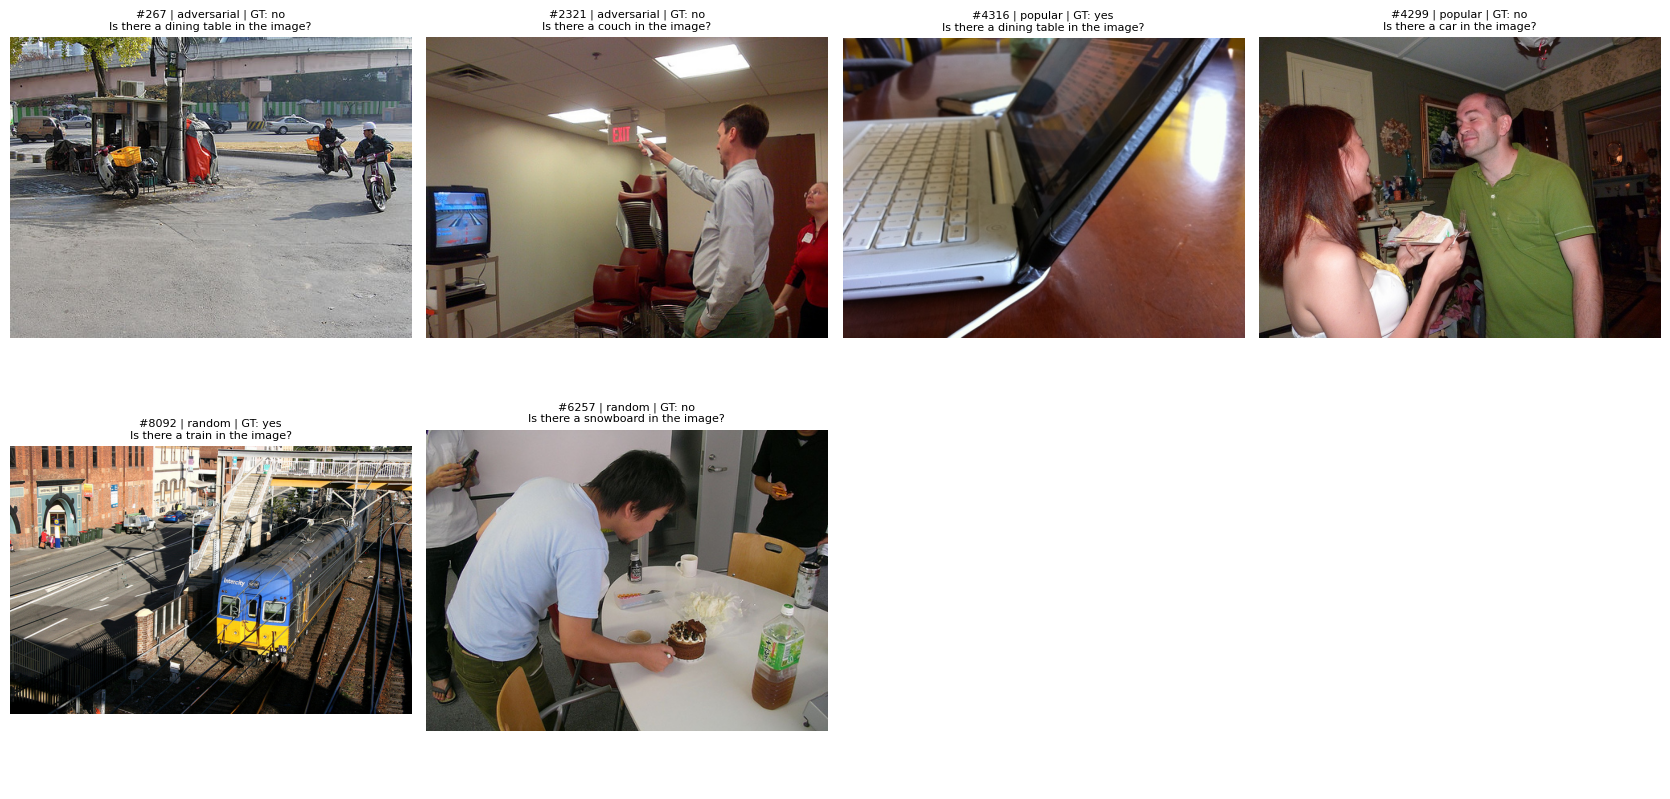

In [10]:
# 2.6 Hiển thị bảng metadata và ảnh thực tế của một số mẫu
display_columns = [c for c in ["id", "question_id", "question", "answer", "category", "image_source"] if c in meta_df.columns]
try:
    display(meta_df[display_columns].head(10))
except NameError:
    print(meta_df[display_columns].head(10).to_string())


def pick_preview_indices(meta, n, seed):
    # Chọn n chỉ số, ưu tiên rải đều theo category
    rng = np.random.default_rng(seed)
    if "category" in meta.columns and meta["category"].notna().any():
        groups = [np.array(list(idx)) for _, idx in meta.groupby("category").groups.items()]
        per_group = max(1, n // len(groups))
        chosen = []
        for group_indices in groups:
            chosen.extend(rng.choice(group_indices, size=min(per_group, len(group_indices)), replace=False).tolist())
        return chosen[:n]
    return rng.choice(len(meta), size=min(n, len(meta)), replace=False).tolist()


def show_samples(dataset, meta, indices, cols=4):
    # Vẽ lưới ảnh kèm câu hỏi và nhãn ground truth (chỉ để kiểm tra dữ liệu)
    rows = (len(indices) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows))
    axes = np.array(axes).reshape(-1)
    for axis in axes:
        axis.axis("off")
    for axis, row_index in zip(axes, indices):
        try:
            axis.imshow(load_image(dataset[int(row_index)]["image"]))
        except ImageLoadError as exc:
            axis.text(0.5, 0.5, f"Ảnh lỗi\n{exc}", ha="center", va="center", wrap=True)
        row = meta.iloc[int(row_index)]
        title = f"#{row_index} | {row.get('category', '')} | GT: {row.get('answer', '')}\n" + \
                textwrap.fill(str(row["question"]), 40)
        axis.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.show()


preview_indices = pick_preview_indices(meta_df, NUM_PREVIEW, SEED)
show_samples(pope_ds, meta_df, preview_indices)

## 2.7 Khoá định danh mẫu và chọn tập mẫu cần chạy
Khoá `sample_key` dùng cho checkpoint/resume: ưu tiên `id` nếu duy nhất, nếu không dùng `id|question_id`, cuối cùng mới dùng vị trí dòng.

In [11]:
# 2.7 Tạo khoá định danh duy nhất cho từng mẫu và chọn tập mẫu chạy
def build_sample_keys(meta):
    # Trả về (danh sách khoá dạng chuỗi, tên cách tạo khoá)
    has_id = "id" in meta.columns and meta["id"].notna().all()
    if has_id and meta["id"].astype(str).is_unique:
        return meta["id"].astype(str).tolist(), "id"
    if has_id and "question_id" in meta.columns and meta["question_id"].notna().all():
        composite = meta["id"].astype(str) + "|" + meta["question_id"].astype(str)
        if composite.is_unique:
            return composite.tolist(), "id|question_id"
    return [f"row{i}" for i in range(len(meta))], "row_index"


def build_run_indices(total, max_samples, sampling, seed):
    # Chọn danh sách chỉ số dòng cần chạy
    if max_samples is None or max_samples >= total:
        return list(range(total))
    if sampling == "random":
        return sorted(np.random.default_rng(seed).choice(total, size=max_samples, replace=False).tolist())
    return list(range(max_samples))


sample_keys, SAMPLE_KEY_MODE = build_sample_keys(meta_df)
run_indices = build_run_indices(len(pope_ds), MAX_SAMPLES, SAMPLING, SEED)
meta_records = meta_df.to_dict("records")  # Truy cập nhanh theo chỉ số dòng

print("Cách tạo khoá mẫu:", SAMPLE_KEY_MODE)
print(f"Số mẫu sẽ chạy: {len(run_indices)} / {len(pope_ds)} (SAMPLING = {SAMPLING})")
if MAX_SAMPLES is not None and SAMPLING == "head" and "category" in meta_df.columns:
    print("Phân bố category của tập chạy:\n", meta_df.iloc[run_indices]["category"].value_counts())

Cách tạo khoá mẫu: id
Số mẫu sẽ chạy: 9000 / 9000 (SAMPLING = head)


---
# PHẦN 3: TẢI MODEL QWEN3-VL-4B-INSTRUCT
Dùng `Qwen3VLForConditionalGeneration` + `AutoProcessor` (không dùng lớp của Qwen2-VL). Dtype: `bfloat16` nếu GPU từ Ampere trở lên (compute capability ≥ 8), ngược lại `float16` (T4/P100 không có bf16 gốc). Không dùng quantization.

In [12]:
# 3.1 Kiểm tra transformers hỗ trợ Qwen3-VL trước khi tải model
import transformers
from transformers import AutoProcessor

print("transformers:", transformers.__version__)
try:
    from transformers import Qwen3VLForConditionalGeneration
except ImportError as exc:
    raise ImportError(f"transformers {transformers.__version__} chưa có Qwen3VLForConditionalGeneration. "
                      f"Cần >= {MIN_TRANSFORMERS}: chạy lại cell 1.2 rồi Restart Session.") from exc
print("Qwen3VLForConditionalGeneration: OK")

transformers: 5.20.2
Qwen3VLForConditionalGeneration: OK


In [13]:
# 3.2 Tải model và processor (chỉ tải một lần)
def select_dtype():
    # Chọn dtype phù hợp với GPU
    if DTYPE_OVERRIDE:
        return getattr(torch, DTYPE_OVERRIDE)
    if not torch.cuda.is_available():
        return torch.float32
    major, _ = torch.cuda.get_device_capability(0)
    return torch.bfloat16 if major >= 8 else torch.float16


def select_device_map():
    # Chọn cách đặt model: 1 GPU nếu đủ VRAM trống, ngược lại để accelerate tự chia ("auto")
    if not torch.cuda.is_available():
        return None
    free_bytes, _ = torch.cuda.mem_get_info(0)
    return {"": 0} if free_bytes / 1024 ** 3 >= 12 else "auto"


def load_model_and_processor():
    # Tải Qwen3-VL và processor với xử lý lỗi rõ ràng
    source = MODEL_PATH or MODEL_NAME
    dtype = select_dtype()
    device_map = select_device_map()
    print(f"Nguồn model: {source} | dtype: {dtype} | device_map: {device_map}")
    try:
        try:
            loaded_model = Qwen3VLForConditionalGeneration.from_pretrained(
                source, torch_dtype=dtype, device_map=device_map, attn_implementation="sdpa")
        except (ValueError, TypeError) as attn_error:
            print("Không dùng được attn_implementation='sdpa', thử lại mặc định:", attn_error)
            loaded_model = Qwen3VLForConditionalGeneration.from_pretrained(
                source, torch_dtype=dtype, device_map=device_map)
        loaded_processor = AutoProcessor.from_pretrained(source)
    except torch.cuda.OutOfMemoryError as exc:
        raise RuntimeError("CUDA OOM khi tải model. Hãy Restart Session, chọn GPU có VRAM lớn hơn "
                           "hoặc đảm bảo không có tiến trình khác dùng GPU.") from exc
    except OSError as exc:
        raise RuntimeError(f"Không tải được model '{source}': {exc}\n"
                           "Kiểm tra Internet hoặc đặt MODEL_PATH tới model trong Kaggle Input.") from exc
    loaded_model.eval()
    loaded_processor.tokenizer.padding_side = "left"  # Bắt buộc cho batch generation
    return loaded_model, loaded_processor


if globals().get("model") is not None and globals().get("processor") is not None:
    print("Model và processor đã được tải trước đó -> không tải lại.")
else:
    model, processor = load_model_and_processor()

# Thông tin model sau khi tải
num_params = sum(p.numel() for p in model.parameters())
print(f"\nLớp model : {type(model).__name__}")
print(f"Số tham số: {num_params / 1e9:.2f} B")
print(f"dtype     : {model.dtype} | device: {model.device}")
if torch.cuda.is_available():
    for gpu_id in range(torch.cuda.device_count()):
        print(f"GPU {gpu_id} VRAM đã cấp phát: {torch.cuda.memory_allocated(gpu_id) / 1024 ** 3:.2f} GB")

Nguồn model: Qwen/Qwen3-VL-4B-Instruct | dtype: torch.float16 | device_map: {'': 0}


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

... (5 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]


Lớp model : Qwen3VLForConditionalGeneration
Số tham số: 4.44 B
dtype     : torch.float16 | device: cuda:0
GPU 0 VRAM đã cấp phát: 8.27 GB
GPU 1 VRAM đã cấp phát: 0.00 GB


---
# PHẦN 4: THIẾT KẾ PROMPT INFERENCE
Prompt chỉ chứa `question`; ảnh được đưa qua placeholder ảnh của chat template. Model được yêu cầu trả lời đúng một từ `Yes` hoặc `No`, không giải thích.

Chuẩn hoá đầu ra: lấy từ đầu tiên của câu trả lời (bỏ dấu câu, không phân biệt hoa thường). Nếu không phải `yes`/`no` thì gán `Invalid` và `status = invalid_output` — **không** âm thầm chuyển thành Yes/No. Văn bản gốc được lưu ở cột `raw_output` để truy vết.

In [14]:
# 4.1 Prompt và hàm chuẩn hoá đầu ra
PROMPT_TEMPLATE = (
    "Answer the following question based only on the provided image.\n\n"
    "Question: {question}\n\n"
    "Respond with exactly one word: Yes or No.\n\n"
    "Do not provide explanations."
)

STATUS_SUCCESS = "success"
STATUS_INVALID = "invalid_output"
STATUS_ERROR = "error"


def build_prompt(question):
    # Tạo nội dung prompt từ câu hỏi (chỉ dùng question)
    return PROMPT_TEMPLATE.format(question=str(question).strip())


def build_messages(question):
    # Tạo cấu trúc hội thoại: 1 ảnh + 1 đoạn text
    return [{"role": "user",
             "content": [{"type": "image"}, {"type": "text", "text": build_prompt(question)}]}]


def normalize_answer(raw_text):
    # Chuẩn hoá chuỗi sinh ra thành (nhãn, status); nhãn là Yes / No / Invalid
    cleaned = re.sub(r"^[\W_]+", "", str(raw_text).strip().lower())
    match = re.match(r"(yes|no)\b", cleaned)
    if match:
        return match.group(1).capitalize(), STATUS_SUCCESS
    return "Invalid", STATUS_INVALID


# Kiểm thử nhanh hàm chuẩn hoá trên các chuỗi mẫu
for sample_text in ["Yes", "no", " No.", "Yes, there is", "Maybe", "", "Nobody", "Not sure"]:
    print(f"{sample_text!r:<16} -> {normalize_answer(sample_text)}")
print("\nPrompt mẫu:\n" + build_prompt("Is there a dog in the image?"))

'Yes'            -> ('Yes', 'success')
'no'             -> ('No', 'success')
' No.'           -> ('No', 'success')
'Yes, there is'  -> ('Yes', 'success')
'Maybe'          -> ('Invalid', 'invalid_output')
''               -> ('Invalid', 'invalid_output')
'Nobody'         -> ('Invalid', 'invalid_output')
'Not sure'       -> ('Invalid', 'invalid_output')

Prompt mẫu:
Answer the following question based only on the provided image.

Question: Is there a dog in the image?

Respond with exactly one word: Yes or No.

Do not provide explanations.


---
# PHẦN 5: XÂY DỰNG HÀM INFERENCE
- `run_inference(question, image)`: một mẫu, có xử lý lỗi riêng và tự thử lại với ảnh nhỏ hơn khi gặp CUDA OOM.
- `run_inference_batch(questions, images)`: nhiều mẫu cùng lúc (khi `BATCH_SIZE > 1`); nếu batch lỗi sẽ tự quay về chạy từng mẫu.

Hàm chỉ nhận `question` và `image` — không có tham số nào cho ground truth.

In [15]:
# 5.1 Hàm inference cho một mẫu và cho batch
def free_memory():
    # Giải phóng bộ nhớ CPU/GPU không cần thiết
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def resize_if_needed(image, max_side):
    # Thu nhỏ ảnh nếu cạnh dài vượt max_side để tiết kiệm VRAM
    width, height = image.size
    longest = max(width, height)
    if max_side and longest > max_side:
        scale = max_side / longest
        return image.resize((max(1, int(width * scale)), max(1, int(height * scale))), Image.BICUBIC)
    return image


def make_result(prediction, raw_output, status, error):
    # Đóng gói kết quả của một mẫu
    return {"prediction": prediction, "raw_output": raw_output, "status": status, "error": error}


def generate_answers(questions, images):
    # Sinh câu trả lời cho danh sách (question, PIL image); trả về danh sách chuỗi
    texts = [processor.apply_chat_template(build_messages(q), tokenize=False, add_generation_prompt=True)
             for q in questions]
    inputs = processor(text=texts, images=images, return_tensors="pt", padding=True)
    inputs = inputs.to(model.device)
    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)  # Đồng bộ dtype với model

    generation_kwargs = {"max_new_tokens": MAX_NEW_TOKENS, "do_sample": DO_SAMPLE}
    if DO_SAMPLE:
        generation_kwargs["temperature"] = TEMPERATURE

    output_ids = None
    try:
        with torch.inference_mode():
            output_ids = model.generate(**inputs, **generation_kwargs)
        prompt_length = inputs["input_ids"].shape[1]
        new_tokens = output_ids[:, prompt_length:]  # Bỏ phần prompt, chỉ giữ token mới sinh
        return processor.batch_decode(new_tokens, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    finally:
        # Không giữ tensor không cần thiết
        del inputs
        if output_ids is not None:
            del output_ids


def run_inference(question, image):
    # Chạy VLM cho một mẫu; trả về dict(prediction, raw_output, status, error)
    try:
        pil_image = load_image(image)
    except ImageLoadError as exc:
        return make_result(None, None, STATUS_ERROR, f"image_error: {exc}")

    side_candidates = [MAX_IMAGE_SIDE] + [s for s in OOM_FALLBACK_SIDES if MAX_IMAGE_SIDE is None or s < MAX_IMAGE_SIDE]
    last_error = "unknown"
    for max_side in side_candidates:
        try:
            raw_text = generate_answers([question], [resize_if_needed(pil_image, max_side)])[0]
            label, status = normalize_answer(raw_text)
            return make_result(label, raw_text.strip(), status, None)
        except torch.cuda.OutOfMemoryError:
            free_memory()
            last_error = f"CUDA OOM (max_side={max_side})"  # Thử lại với ảnh nhỏ hơn
        except Exception as exc:
            free_memory()
            return make_result(None, None, STATUS_ERROR, f"{type(exc).__name__}: {exc}")
    return make_result(None, None, STATUS_ERROR, last_error)


def run_inference_batch(questions, images):
    # Chạy batch; mẫu lỗi ảnh được loại riêng, nếu cả batch lỗi thì chạy lại từng mẫu
    if len(questions) == 1:
        return [run_inference(questions[0], images[0])]
    results = [None] * len(questions)
    valid_positions, valid_images = [], []
    for position, image in enumerate(images):
        try:
            valid_images.append(resize_if_needed(load_image(image), MAX_IMAGE_SIDE))
            valid_positions.append(position)
        except ImageLoadError as exc:
            results[position] = make_result(None, None, STATUS_ERROR, f"image_error: {exc}")
    if valid_positions:
        try:
            raw_texts = generate_answers([questions[p] for p in valid_positions], valid_images)
            for position, raw_text in zip(valid_positions, raw_texts):
                label, status = normalize_answer(raw_text)
                results[position] = make_result(label, raw_text.strip(), status, None)
        except Exception:
            free_memory()  # Batch lỗi (thường do OOM): quay về chạy từng mẫu
            for position in valid_positions:
                results[position] = run_inference(questions[position], images[position])
    return results

In [16]:
# 5.2 Chạy thử trên một vài mẫu để kiểm tra pipeline trước khi chạy toàn bộ
smoke_indices = run_indices[:3]
for row_index in smoke_indices:
    smoke_result = run_inference(meta_records[row_index]["question"], pope_ds[int(row_index)]["image"])
    print(f"#{row_index} | Q: {meta_records[row_index]['question']}")
    print("   ->", smoke_result)
free_memory()

#0 | Q: Is there a snowboard in the image?
   -> {'prediction': 'Yes', 'raw_output': 'Yes', 'status': 'success', 'error': None}
#1 | Q: Is there a backpack in the image?
   -> {'prediction': 'No', 'raw_output': 'No', 'status': 'success', 'error': None}
#2 | Q: Is there a person in the image?
   -> {'prediction': 'Yes', 'raw_output': 'Yes', 'status': 'success', 'error': None}


---
# PHẦN 6: CHẠY INFERENCE TRÊN DATASET
Mỗi mẫu được ghi thành một dòng JSON (append) vào `vlm_predictions.jsonl` theo từng lô `SAVE_INTERVAL` mẫu (checkpoint). Khi chạy lại với `RESUME = True`:
- các mẫu đã hoàn thành (`success` / `invalid_output`) được bỏ qua;
- các mẫu `error` được chạy lại nếu `RETRY_FAILED = True`; bản ghi lỗi cũ bị loại khỏi file trước khi ghi tiếp nên **không bị trùng**.

Nếu phiên Kaggle mới chưa có output cũ, hãy thêm output phiên trước làm Input và đặt `RESUME_FROM` tới file `.jsonl` của nó.

In [17]:
# 6.1 Hàm đọc / ghi checkpoint và tạo bản ghi kết quả
OUTPUT_COLUMNS = ["id", "question_id", "question", "prediction", "image_source", "category", "status", "error"]
EXTRA_COLUMNS = ["raw_output", "row_index", "sample_key"]  # Cột phụ để truy vết (evaluation không bắt buộc)


def json_default(value):
    # Chuyển kiểu numpy sang kiểu Python để ghi JSON
    if isinstance(value, np.generic):
        return value.item()
    return str(value)


def clean_value(value):
    # NaN/None -> None; numpy scalar -> Python scalar
    if value is None:
        return None
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and np.isnan(value):
        return None
    return value


def build_record(row_index, result):
    # Tạo bản ghi cho một mẫu (không chứa bytes ảnh)
    meta = meta_records[row_index]
    return {
        "id": clean_value(meta.get("id")),
        "question_id": clean_value(meta.get("question_id")),
        "question": clean_value(meta.get("question")),
        "prediction": result["prediction"],
        "image_source": clean_value(meta.get("image_source")),
        "category": clean_value(meta.get("category")),
        "status": result["status"],
        "error": result["error"],
        "raw_output": result["raw_output"],
        "row_index": int(row_index),
        "sample_key": sample_keys[row_index],
    }


def read_jsonl_records(path):
    # Đọc JSONL thành dict sample_key -> bản ghi (bản ghi sau ghi đè bản ghi trước); bỏ qua dòng hỏng
    records, broken_lines = {}, 0
    if path is None or not Path(path).exists():
        return records, broken_lines
    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            try:
                record = json.loads(line)
                records[record["sample_key"]] = record
            except (json.JSONDecodeError, KeyError):
                broken_lines += 1  # Dòng cuối có thể bị cắt khi notebook bị ngắt đột ngột
    return records, broken_lines


def write_jsonl_atomic(path, records):
    # Ghi lại toàn bộ file JSONL qua file tạm rồi thay thế (an toàn khi bị ngắt giữa chừng)
    temp_path = Path(str(path) + ".tmp")
    with open(temp_path, "w", encoding="utf-8") as file:
        for record in records:
            file.write(json.dumps(record, ensure_ascii=False, default=json_default) + "\n")
    temp_path.replace(path)


def append_jsonl(path, records):
    # Ghi nối thêm các bản ghi mới (checkpoint)
    with open(path, "a", encoding="utf-8") as file:
        for record in records:
            file.write(json.dumps(record, ensure_ascii=False, default=json_default) + "\n")
        file.flush()
        os.fsync(file.fileno())

In [18]:
# 6.2 Chuẩn bị resume: xác định các mẫu đã xong và các mẫu còn phải chạy
run_keys = {sample_keys[i] for i in run_indices}

resume_source = None
if RESUME:
    if JSONL_PATH.exists():
        resume_source = JSONL_PATH
    elif RESUME_FROM and Path(RESUME_FROM).exists():
        resume_source = Path(RESUME_FROM)

existing_records, broken_line_count = read_jsonl_records(resume_source) if resume_source else ({}, 0)
done_statuses = {STATUS_SUCCESS, STATUS_INVALID}
kept_records = [r for r in existing_records.values()
                if (r.get("status") in done_statuses or not RETRY_FAILED)]

# Ghi lại file checkpoint đã được làm sạch (loại bản ghi lỗi cần chạy lại, loại dòng hỏng, tránh trùng)
write_jsonl_atomic(JSONL_PATH, kept_records)
done_keys = {r["sample_key"] for r in kept_records}
pending_indices = [i for i in run_indices if sample_keys[i] not in done_keys]

print("Nguồn resume:", resume_source if resume_source else "(không có - chạy mới)")
print(f"Bản ghi hợp lệ đã có: {len(kept_records)} | dòng hỏng bỏ qua: {broken_line_count}")
print(f"Cần chạy: {len(pending_indices)} / {len(run_indices)} mẫu")

Nguồn resume: (không có - chạy mới)
Bản ghi hợp lệ đã có: 0 | dòng hỏng bỏ qua: 0
Cần chạy: 9000 / 9000 mẫu


In [19]:
# 6.3 Chạy inference có checkpoint; luôn ghi nốt buffer khi bị ngắt hoặc xảy ra lỗi
def fetch_image_data(row_index):
    # Đọc dữ liệu ảnh của một dòng; trả về (dữ liệu, thông báo lỗi)
    try:
        return pope_ds[int(row_index)]["image"], None
    except Exception as exc:
        return None, f"{type(exc).__name__}: {exc}"


def process_batch(batch_indices):
    # Chạy inference cho một nhóm chỉ số dòng và trả về danh sách bản ghi
    fetched = [fetch_image_data(i) for i in batch_indices]
    results = [None] * len(batch_indices)
    ok_positions = []
    for position, (image_data, fetch_error) in enumerate(fetched):
        if fetch_error:
            results[position] = make_result(None, None, STATUS_ERROR, f"image_fetch_error: {fetch_error}")
        else:
            ok_positions.append(position)
    if ok_positions:
        questions = [meta_records[batch_indices[p]]["question"] for p in ok_positions]
        images = [fetched[p][0] for p in ok_positions]
        for position, result in zip(ok_positions, run_inference_batch(questions, images)):
            results[position] = result
    return [build_record(i, result) for i, result in zip(batch_indices, results)]


buffer_records = []
status_counter = {STATUS_SUCCESS: 0, STATUS_INVALID: 0, STATUS_ERROR: 0}
start_time = time.time()
interrupted = False

progress = tqdm(total=len(pending_indices), desc="Inference")
try:
    for start in range(0, len(pending_indices), BATCH_SIZE):
        batch_indices = pending_indices[start:start + BATCH_SIZE]
        new_records = process_batch(batch_indices)
        buffer_records.extend(new_records)
        for record in new_records:
            status_counter[record["status"]] += 1
        progress.update(len(batch_indices))
        progress.set_postfix(status_counter)
        if len(buffer_records) >= SAVE_INTERVAL:
            append_jsonl(JSONL_PATH, buffer_records)  # Checkpoint
            buffer_records = []
            free_memory()
except KeyboardInterrupt:
    interrupted = True
    print("\nĐã dừng thủ công. Kết quả đã xử lý sẽ được lưu để có thể resume.")
finally:
    if buffer_records:
        append_jsonl(JSONL_PATH, buffer_records)
        buffer_records = []
    progress.close()
    free_memory()

elapsed = time.time() - start_time
print(f"\nHoàn tất lượt chạy trong {elapsed / 60:.1f} phút | {status_counter}")

Inference:   0%|          | 0/9000 [00:00<?, ?it/s]


Hoàn tất lượt chạy trong 60.6 phút | {'success': 9000, 'invalid_output': 0, 'error': 0}


---
# PHẦN 7: LƯU KẾT QUẢ
Tạo `vlm_predictions.csv`, `vlm_predictions.jsonl` (đã khử trùng, sắp theo thứ tự dataset) và `inference_summary.json`.

Quy ước cột `prediction`: `Yes` / `No` (hợp lệ), `Invalid` (model trả lời sai định dạng), rỗng (mẫu lỗi, `status = error`). Notebook evaluation chỉ tính metrics trên `status = success`.

In [20]:
# 7.1 Tổng hợp kết quả cuối cùng và ghi CSV / JSONL
final_map, _ = read_jsonl_records(JSONL_PATH)
final_records = sorted((final_map[k] for k in run_keys if k in final_map), key=lambda r: r["row_index"])

if not final_records:
    raise RuntimeError("Chưa có kết quả nào để lưu.")

final_df = pd.DataFrame(final_records)
for column in OUTPUT_COLUMNS + EXTRA_COLUMNS:
    if column not in final_df.columns:
        final_df[column] = None
final_df = final_df[OUTPUT_COLUMNS + EXTRA_COLUMNS]

# Kiểm tra không trùng khoá
assert final_df["sample_key"].is_unique, "Phát hiện khoá mẫu trùng trong kết quả"

final_df.to_csv(CSV_PATH, index=False, encoding="utf-8")
write_jsonl_atomic(JSONL_PATH, final_records)  # Ghi từ bản ghi gốc (không có NaN) để JSON hợp lệ
print(f"Đã lưu {len(final_df)} dòng:\n - {CSV_PATH}\n - {JSONL_PATH}")

Đã lưu 9000 dòng:
 - /kaggle/working/output/vlm_predictions.csv
 - /kaggle/working/output/vlm_predictions.jsonl


In [21]:
# 7.2 Ghi inference_summary.json
n_success = int((final_df["status"] == STATUS_SUCCESS).sum())
n_invalid = int((final_df["status"] == STATUS_INVALID).sum())
n_error = int((final_df["status"] == STATUS_ERROR).sum())
n_pending = len(run_indices) - len(final_df)

# Số câu trả lời được parse thành công nhưng model có nói thêm chữ ngoài một từ Yes/No
parsed_rows = final_df[final_df["status"] == STATUS_SUCCESS]
extra_text_count = int(sum(
    re.sub(r"[\W_]+", "", str(raw).lower()) != str(pred).lower()
    for raw, pred in zip(parsed_rows["raw_output"], parsed_rows["prediction"])))

summary = {
    "model_name": MODEL_NAME,
    "model_source": MODEL_PATH or MODEL_NAME,
    "dataset_name": DATASET_NAME,
    "dataset_split": SPLIT_NAME,
    "dataset_files": PARQUET_FILES_USED,
    "data_source_mode": DATA_SOURCE,
    "total_samples_in_split": len(pope_ds),
    "total_samples": len(run_indices),
    "processed_samples": len(final_df),
    "pending_samples": n_pending,
    "successful_samples": n_success,
    "failed_samples": n_error,
    "invalid_predictions": n_invalid,
    "yes_count": int((final_df["prediction"] == "Yes").sum()),
    "no_count": int((final_df["prediction"] == "No").sum()),
    "parsed_but_extra_text_count": extra_text_count,
    "sample_key_mode": SAMPLE_KEY_MODE,
    "inference_timestamp_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
    "inference_parameters": {
        "max_samples": MAX_SAMPLES, "sampling": SAMPLING, "seed": SEED, "batch_size": BATCH_SIZE,
        "max_new_tokens": MAX_NEW_TOKENS, "do_sample": DO_SAMPLE,
        "temperature": TEMPERATURE if DO_SAMPLE else None,
        "max_image_side": MAX_IMAGE_SIDE, "oom_fallback_sides": list(OOM_FALLBACK_SIDES),
        "dtype": str(model.dtype), "prompt_template": PROMPT_TEMPLATE,
        "save_interval": SAVE_INTERVAL, "resume": RESUME, "retry_failed": RETRY_FAILED,
    },
    "environment": {
        "python": sys.version.split()[0], "torch": torch.__version__,
        "transformers": transformers.__version__,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    },
    "interrupted": interrupted,
}
with open(SUMMARY_PATH, "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2, default=json_default)
print(json.dumps(summary, ensure_ascii=False, indent=2, default=json_default))
if n_pending > 0:
    print(f"\nCòn {n_pending} mẫu chưa xử lý. Chạy lại cell 6.2 -> 6.3 -> 7.1 -> 7.2 để tiếp tục (resume).")

{
  "model_name": "Qwen/Qwen3-VL-4B-Instruct",
  "model_source": "Qwen/Qwen3-VL-4B-Instruct",
  "dataset_name": "lmms-lab-encoder/POPE",
  "dataset_split": "test",
  "dataset_files": [
    "data/test-00000-of-00003.parquet",
    "data/test-00001-of-00003.parquet",
    "data/test-00002-of-00003.parquet"
  ],
  "data_source_mode": "hub_parquet",
  "total_samples_in_split": 9000,
  "total_samples": 9000,
  "processed_samples": 9000,
  "pending_samples": 0,
  "successful_samples": 9000,
  "failed_samples": 0,
  "invalid_predictions": 0,
  "yes_count": 3886,
  "no_count": 5114,
  "parsed_but_extra_text_count": 0,
  "sample_key_mode": "id",
  "inference_timestamp_utc": "2026-11-20T11:01:26.591321+00:00",
  "inference_parameters": {
    "max_samples": null,
    "sampling": "head",
    "seed": 42,
    "batch_size": 1,
    "max_new_tokens": 8,
    "do_sample": false,
    "temperature": null,
    "max_image_side": 1024,
    "oom_fallback_sides": [
      768,
      512,
      384
    ],
    "dtyp

In [22]:
# 7.3 Kết quả cuối: 10 mẫu đầu, thống kê Yes/No, mẫu lỗi, đường dẫn file
try:
    display(final_df.head(10))
except NameError:
    print(final_df.head(10).to_string())

print("\nThống kê prediction:")
print(final_df["prediction"].value_counts(dropna=False))
print(f"\nYes: {summary['yes_count']} | No: {summary['no_count']} | Invalid: {n_invalid} | Lỗi (error): {n_error}")

if n_error:
    print("\nMột số mẫu lỗi:")
    print(final_df[final_df["status"] == STATUS_ERROR][["id", "question", "error"]].head(10).to_string())

print("\nFile kết quả:")
for output_path in [CSV_PATH, JSONL_PATH, SUMMARY_PATH]:
    print(f" - {output_path.resolve()}  ({output_path.stat().st_size / 1024:.1f} KB)")

,id,question_id,question,prediction,image_source,category,status,error,raw_output,row_index,sample_key
0,0,1,Is there a snowboard in the image?,Yes,COCO_val2014_000000310196,adversarial,success,None,Yes,0,0
1,1,2,Is there a backpack in the image?,No,COCO_val2014_000000310196,adversarial,success,None,No,1,1
2,2,3,Is there a person in the image?,Yes,COCO_val2014_000000310196,adversarial,success,None,Yes,2,2
3,3,4,Is there a car in the image?,No,COCO_val2014_000000310196,adversarial,success,None,No,3,3
4,4,5,Is there a skis in the image?,No,COCO_val2014_000000310196,adversarial,success,None,No,4,4
5,5,6,Is there a dog in the image?,No,COCO_val2014_000000310196,adversarial,success,None,No,5,5
6,6,7,Is there a truck in the image?,Yes,COCO_val2014_000000210789,adversarial,success,None,Yes,6,6
7,7,8,Is there a car in the image?,Yes,COCO_val2014_000000210789,adversarial,success,None,Yes,7,7
8,8,9,Is there a person in the image?,Yes,COCO_val2014_000000210789,adversarial,success,None,Yes,8,8
9,9,10,Is there a dining table in the image?,No,COCO_val2014_000000210789,adversarial,success,None,No,9,9



Thống kê prediction:
prediction
No     5114
Yes    3886
Name: count, dtype: int64

Yes: 3886 | No: 5114 | Invalid: 0 | Lỗi (error): 0

File kết quả:
 - /kaggle/working/output/vlm_predictions.csv  (901.2 KB)
 - /kaggle/working/output/vlm_predictions.jsonl  (2386.5 KB)
 - /kaggle/working/output/inference_summary.json  (1.4 KB)
